# Exposure at default and the credit conversion factor: the terminology trap

- **Level:** 1, Fundamentals
- **Prerequisites:** notebook 01 of this topic (the workout LGD) and notebooks 01 and 02 of topic 01
- **Reading time:** about 35 minutes

## Objectives

By the end of this notebook you can:

- compute the exposure at default of a revolving line from a credit conversion factor, and go back from the EAD to the factor;
- say which of the three numbers called "the CCF" a document means: the EU factor on the undrawn amount, the US loan equivalent and the Qi (2009) ratios to the balance and to the limit;
- choose and read the three reference-date designs (fixed horizon, cohort, variable horizon) with `reference_indices` and `ccf_observations`, and say when a factor is undefined;
- treat a factor below 0 or above 1 in each of the four ways of `treat_ccf`, and say what each does to the mean;
- read the distribution of the factors of the C09 generator and the small-undrawn rule.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.lgd_ead import ccf, workout

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
matplotlib 3.11.2


## Data

Two committed artifacts of case C09, the exposure at default and the conversion factor of revolving lines: `data/derived/C09/level-0.json` (the variant for acceleration level 0) and `data/derived/C09/models-generator.json` (the generator and the designs behind every level). C09 has **a known truth**. Its lines are produced by a generator whose field structure and marginal distributions follow the Federal Reserve's 2025 hypothetical card portfolios, and the generator draws balances with a conversion factor that is its own parameter. Every estimate is therefore shown beside the truth it should recover, and the data are synthetic, not observations of any lender (the artifact says so in `outputs.generator.notice`).

Level 0 means no acceleration: the undrawn amount is drawn at a constant rate over the twelve months before the default. Notebooks 05 and 07 of this topic raise the level; here we use level 0 to learn the vocabulary. Like C08, the artifacts were baked by an older engine than the installed one, and the next cell prints both versions.

In [2]:
# Open the two artifacts, print the generator's notice, the known CCF, the convention and the designs
ROOT = Path("../../..").resolve()
DERIVED = ROOT / "data" / "derived" / "C09"
level0 = json.loads((DERIVED / "level-0.json").read_text(encoding="utf-8"))
gen = json.loads((DERIVED / "models-generator.json").read_text(encoding="utf-8"))
out = level0["outputs"]
print("case:", level0["case_id"], "| variant:", level0["variant_id"], "| truth status:", "synthetic, known truth")
print("baked by riskvalidation:", level0["provenance"]["riskvalidation_version"], "| installed:", rv.__version__)
print()
print(out["generator"]["notice"]["en"])
print()
print("known CCF of level 0:", out["generator"]["true_ccf"]["value"])
print("convention:", out["convention"]["name"], "|", out["convention"]["formula"])
print(out["convention"]["definition"]["en"])
print(out["convention"]["us_terms"]["en"])
for design in gen["fit"]["designs"]:
    print("-", design["label"]["en"])

case: C09 | variant: level-0 | truth status: synthetic, known truth
baked by riskvalidation: 1.0.1 | installed: 1.0.1

Synthetic data: these are generated revolving credit lines, not observations of any portfolio and not evidence about any bank or card issuer. Their field structure and marginals follow the Federal Reserve's 2025 hypothetical card portfolios; the CCF each level draws balances with is the generator's own parameter, so every estimate is shown beside the truth it is meant to recover. Amounts in USD.

known CCF of level 0: 0.6
convention: eu-undrawn | CCF = (EAD - E(t_r)) / (L(t_r) - E(t_r))
CCF = (EAD - drawn at the reference date) / (limit - drawn at the reference date): the share of the undrawn amount drawn by default.
The same ratio is the loan equivalent (LEQ) in US terms; Qi (2009) calls EAD over outstanding the CCF and EAD over the limit the EADF.
- Fixed horizon: 12 months before default
- Yearly cohort: the cohort start
- Variable horizon: quarterly reference dates

## Method

### Step 1: one facility, three numbers

A revolving line has a limit $L$ and a drawn balance $E$ at a reference date, and the bank's exposure at default is $EAD$. The research for this product records the EU convention as

$$CCF = \frac{EAD - E(t_r)}{L(t_r) - E(t_r)} \qquad\Longleftrightarrow\qquad EAD = E(t_r) + CCF\,\big(L(t_r) - E(t_r)\big)$$

with $t_r$ the reference date before the default date $t_d$: the share of the undrawn amount that is drawn by default. In US terms the same ratio is the loan equivalent (LEQ). Qi (2009) uses the same words for other ratios: his "CCF" is $EAD / E$ (over the balance) and his "EADF" is $EAD / L$ (over the limit). (Sources: the docstring of `riskvalidation.lgd_ead.ccf` at release 0.8.1, and Qi 2009, OCC Economics Working Paper 2009-2, as named there.) A document that says "the CCF" without naming the denominator can mean any of the three, and this is the terminology trap.

`to_us_terms(drawn, limit, ead)` returns the three numbers for each facility, and `ead_from_ccf(drawn, limit, ccf)` goes back. The next cell invents three facilities: a line that is part drawn at default, one that is fully drawn and one that is over its limit.

In [3]:
# Three invented facilities: the three numbers called the CCF, and the EAD recovered from the EU factor
names = ["part drawn", "fully drawn", "over the limit"]
drawn = np.array([60.0, 20.0, 90.0])
limit = np.array([100.0, 100.0, 100.0])
ead = np.array([85.0, 100.0, 120.0])

leq, ccf_us, eadf = ccf.to_us_terms(drawn, limit, ead)
print(f"{'':20s} {'E':>5s} {'L':>5s} {'EAD':>5s} | {'EU factor (EAD-E)/(L-E)':>46s} | {'EAD/E':>7s} | {'EAD/L':>7s}")
for i, name in enumerate(names):
    print(f"{name:20s} {drawn[i]:5.0f} {limit[i]:5.0f} {ead[i]:5.0f} | {leq[i]:46.4f} | {ccf_us[i]:7.4f} | {eadf[i]:7.4f}")
print("EAD recovered from the EU factor:", ccf.ead_from_ccf(drawn, limit, leq))

                         E     L   EAD |                        EU factor (EAD-E)/(L-E) |   EAD/E |   EAD/L
part drawn              60   100    85 |                                         0.6250 |  1.4167 |  0.8500
fully drawn             20   100   100 |                                         1.0000 |  5.0000 |  1.0000
over the limit          90   100   120 |                                         3.0000 |  1.3333 |  1.2000
EAD recovered from the EU factor: [ 85. 100. 120.]


The same facility is 0.625, 1.4167 and 0.85 depending on the ratio. The EU factor is exactly 1 for the fully drawn line (it drew all of its undrawn amount) and 3 for the line over its limit (the limit was 100, the balance 90, and the bank ended up 30 above the balance: three times the 10 that was undrawn). Notice what the factor does when the undrawn amount is small: a few currency units of undrawn amount in the denominator make the ratio explode, which is why step 5 comes back to it.

### Step 2: which month is the reference date?

The factor needs a reference date $t_r$ before the default, and the choice is a model design, not a detail. The engine's `reference_indices(design, default_index, ...)` gives the months of a facility's path for each design:

- `fixed-horizon`: one date, `horizon` months before the default (`t_d - h`);
- `cohort`: one date, the start of the calendar cohort that contains the default (the caller gives `cohort_start_index`);
- `variable-horizon`: `n_reference` dates, `t_d - h + k * step` for `k = 0 ... n_reference - 1`.

(Source: the docstring of `reference_indices`; the three designs follow Moral (2006) as the research summarises it, and the engine marks the detail UNVERIFIED because that chapter was not read.) A reference date that is negative or not before the default raises an error. `ccf_observations(drawn, limit, ead, reference_index)` then returns the factor and the undrawn amount at each date, and `aggregate_ccf` combines them as the mean of the factors or as the pooled ratio $\sum (CCF\,U) / \sum U$ of the undrawn amounts $U$.

The next cell invents the monthly path of one line that defaults at month 20 with an EAD of 88, and of a second line that is fully drawn from month 14. It prints the months each design picks and the factor each gives.

In [4]:
# Two invented monthly paths, the reference months of each design, the factors and their two aggregations
months = np.arange(21)
limit_path = np.full(21, 100.0)
drawn_a = np.linspace(30.0, 85.0, 21)
drawn_b = np.minimum(np.linspace(40.0, 130.0, 21), 100.0)
default_month = 20
DESIGN_NAME = {"fixed-horizon": "fixed horizon", "cohort": "cohort", "variable-horizon": "variable horizon"}
designs = {
    "fixed-horizon": dict(horizon=12),
    "cohort": dict(cohort_start_index=12),
    "variable-horizon": dict(horizon=12, n_reference=4, step=3),
}
for label, path, final_ead in (("line 1, EAD 88", drawn_a, 88.0), ("line 2 (fully drawn from month 14), EAD 100", drawn_b, 100.0)):
    print(label)
    for design, kwargs in designs.items():
        idx = ccf.reference_indices(design, default_month, **kwargs)
        factors, undrawn = ccf.ccf_observations(path, limit_path, final_ead, idx)
        line = f"  {DESIGN_NAME[design]:19s} months {idx.tolist()} factors {np.round(factors, 4).tolist()} undrawn {np.round(undrawn, 2).tolist()}"
        if np.isfinite(factors).any():
            line += f" | mean {ccf.aggregate_ccf(factors, undrawn, 'mean'):.4f} pooled {ccf.aggregate_ccf(factors, undrawn, 'pooled'):.4f}"
        print(line)

line 1, EAD 88
  fixed horizon       months [8] factors [0.75] undrawn [48.0] | mean 0.7500 pooled 0.7500
  cohort              months [12] factors [0.6757] undrawn [37.0] | mean 0.6757 pooled 0.6757
  variable horizon    months [8, 11, 14, 17] factors [0.75, 0.6981, 0.619, 0.4839] undrawn [48.0, 39.75, 31.5, 23.25] | mean 0.6378 pooled 0.6632
line 2 (fully drawn from month 14), EAD 100
  fixed horizon       months [8] factors [1.0] undrawn [24.0] | mean 1.0000 pooled 1.0000
  cohort              months [12] factors [1.0] undrawn [6.0] | mean 1.0000 pooled 1.0000
  variable horizon    months [8, 11, 14, 17] factors [1.0, 1.0, nan, nan] undrawn [24.0, 10.5, 0.0, 0.0] | mean 1.0000 pooled 1.0000


Two things to read in the output. First, line 1 gives a different factor under each design: 0.75 at the fixed horizon, 0.6757 at the cohort start, and 0.6378 (mean) or 0.6632 (pooled) for the variable horizon. In this invented path the balance keeps growing towards the default, so a later reference date leaves less undrawn amount and the same EAD is a smaller share of it. The factor is a property of the design as much as of the line, and C09 measures that on a known truth in notebook 05. Second, for the second line the months where the balance has reached the limit give `nan`: when the undrawn amount is not positive the factor is undefined, and the engine says so with a missing value, never with 0 or 1. A defaulter whose every reference month is fully drawn simply has no factor, and C09 counts those defaulters.

### Step 3: a factor below 0 or above 1

A factor below 0 means the balance fell between the reference date and the default; above 1 means the bank ended above the limit. Both happen. `treat_ccf(ccf, treatment)` offers four treatments and reports what it did:

- `none`: keep every value (flag them with `range_flag`);
- `censor`: drop the observations outside [0, 1];
- `floor-cap`: clip to [0, 1], which the engine documents as biasing the EAD;
- `bounded-scale`: return the clipped values as the response of a fractional logit.

Missing factors are dropped first and counted, and the counts of values below 0 and above 1 are taken on the input whatever the treatment. The next cell applies the four treatments to eight invented factors.

In [5]:
# Flag eight invented factors and apply the four treatments of treat_ccf
factors = np.array([-0.40, 0.10, 0.35, 0.60, 0.80, 1.00, 1.70, np.nan])
WORDS = {"below-zero": "below 0", "in-range": "in [0, 1]", "above-one": "above 1"}
print("range_flag:", [WORDS[f] for f in workout.range_flag(np.nan_to_num(factors, nan=0.5))])
LABELS = {"none": "none", "censor": "censor", "floor-cap": "floor-cap", "bounded-scale": "bounded-scale"}
for treatment in ccf.TREATMENTS:
    treated = ccf.treat_ccf(factors, treatment)
    print(f"{LABELS[treatment]:16s} kept {treated.values.size} dropped {treated.n_dropped} below 0 {treated.n_below_zero} above 1 {treated.n_above_one} mean factor {treated.values.mean():.4f}")

range_flag: ['below 0', 'in [0, 1]', 'in [0, 1]', 'in [0, 1]', 'in [0, 1]', 'in [0, 1]', 'above 1', 'in [0, 1]']
none             kept 7 dropped 1 below 0 1 above 1 1 mean factor 0.5929
censor           kept 5 dropped 3 below 0 1 above 1 1 mean factor 0.5700
floor-cap        kept 7 dropped 1 below 0 1 above 1 1 mean factor 0.5500
bounded-scale    kept 7 dropped 1 below 0 1 above 1 1 mean factor 0.5500


### Step 4: the distribution of the factors in C09

Now the committed generator. The artifact `level-0.json` holds the histogram of the factors of the fixed-horizon design (`outputs.ccf_distribution`): the bin edges, the count per bin, and the counts below 0 and above 1. The cell checks that the counts add up, prints the shares and draws the histogram with the known CCF marked. The generator knows the truth (0.6 at level 0), so a vertical line at it shows where the factors should centre.

design: fixed horizon | defaulters with a defined factor: 30,154 | counted in the bins: 30,154
below 0: 507 (1.68%) | above 1: 1,940 (6.43%)
known CCF: 0.6


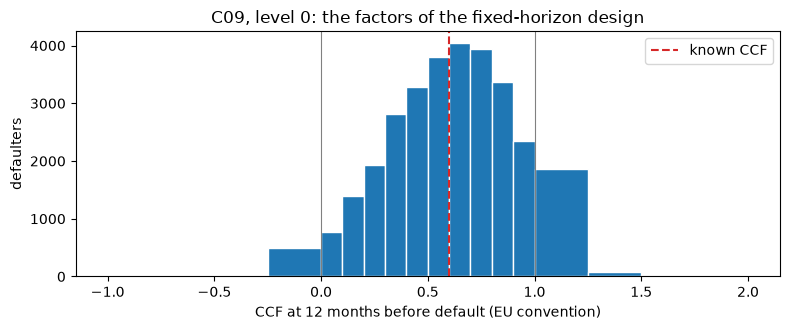

In [6]:
# Check the histogram counts, print the shares outside [0, 1] and draw the distribution with the known CCF
dist = out["ccf_distribution"]
edges = np.array(dist["edges"])
counts = np.array(dist["counts"])
print(f"design: {DESIGN_NAME[dist['design']]} | defaulters with a defined factor: {dist['n']:,} | counted in the bins: {counts.sum():,}")
print(f"below 0: {dist['n_below_zero']:,} ({dist['n_below_zero'] / dist['n']:.2%}) | above 1: {dist['n_above_one']:,} ({dist['n_above_one'] / dist['n']:.2%})")
truth = out["generator"]["true_ccf"]["value"]
print("known CCF:", truth)

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.bar(edges[:-1], counts, width=np.diff(edges), align="edge", edgecolor="white", color="tab:blue")
ax.axvline(truth, color="tab:red", linestyle="--", label="known CCF")
ax.axvline(0.0, color="grey", linewidth=0.8)
ax.axvline(1.0, color="grey", linewidth=0.8)
ax.set_xlabel("CCF at 12 months before default (EU convention)")
ax.set_ylabel("defaulters")
ax.set_title("C09, level 0: the factors of the fixed-horizon design")
ax.legend()
fig.tight_layout()
plt.show()

### Step 5: when the undrawn amount is small

If a line has only a few currency units undrawn at the reference date, the ratio $(EAD - E)/(L - E)$ divides by almost nothing and is unstable. Qi (2009) switches to a different ratio below a threshold of undrawn amount; `small_undrawn_rule(drawn, limit, ead, threshold)` returns which facilities are switched and the ratio to use: $EAD/L$ where switched, the EU factor elsewhere. The threshold is a parameter in the currency of the amounts. The next cell invents three facilities, two of them with less than 50 undrawn, and then prints what the C09 artifact records about the rule: it computes the count of facilities that would be switched at a threshold of 50 USD and states that the rule is **not applied** in the baked factors.

In [7]:
# Apply the small-undrawn rule to three invented facilities and read what the artifact records about it
d = np.array([4_980.0, 4_000.0, 1_000.0])
lim = np.array([5_000.0, 4_030.0, 5_000.0])
e = np.array([5_020.0, 4_100.0, 3_000.0])
switched, ratio = ccf.small_undrawn_rule(d, lim, e, threshold=50.0)
for i in range(3):
    print(f"facility {i + 1}: undrawn {lim[i] - d[i]:7.1f} switched {bool(switched[i])!s:5s} ratio used {ratio[i]:.4f}")

small = out["small_undrawn"]
print(f"artifact: threshold {small['threshold']} {small['currency']} | rule applied: {small['applied']} | facilities that would be switched: {small['n_switched']:,} | reference: {small['reference']}")

facility 1: undrawn    20.0 switched True  ratio used 1.0040
facility 2: undrawn    30.0 switched True  ratio used 1.0174
facility 3: undrawn  4000.0 switched False ratio used 0.5000
artifact: threshold 50.0 USD | rule applied: False | facilities that would be switched: 8,903 | reference: Qi (2009), OCC Economics Working Paper 2009-2


## Results

- **One facility, three numbers.** The part-drawn line (balance 60, limit 100, EAD 85) has an EU factor of 0.6250, a ratio to the balance of 1.4167 and a ratio to the limit of 0.8500. The fully drawn line has a ratio to the balance of 5.0000 and the line over its limit an EU factor of 3.0000. `ead_from_ccf` returns the three invented EADs (85, 100 and 120) from the EU factors, so the identity runs both ways.
- **The reference date is a design.** For line 1 the fixed-horizon factor is 0.7500, the cohort-start factor 0.6757 and the variable-horizon factor 0.6378 as a mean and 0.6632 pooled. For line 2 the months where the balance had reached the limit give a missing factor, not a 0 or a 1.
- **Treating a factor outside [0, 1] changes the mean.** On eight invented factors, keeping all gives 0.5929, censoring gives 0.5700 (it drops three observations: the one below 0, the one above 1 and the missing one) and flooring and capping, or the bounded scale, gives 0.5500.
- **C09 has factors outside [0, 1] and a known centre.** Of 30,154 defaulters with a defined factor at the 12-month horizon, 507 (1.68%) are below 0 and 1,940 (6.43%) above 1, around a known CCF of 0.6. The small-undrawn rule would switch 8,903 facilities at a threshold of 50 USD, and the baked factors do not apply it.

What the notebook does not do: it does not say which convention a regulator or a bank should use, only what each one means. The three invented facilities and the two paths exist to show the arithmetic and carry no information about any lender. The next notebook returns to LGD and fits the ladder of models on the C08 cohorts.

## Summary

- The EU factor is $(EAD - E)/(L - E)$, the share of the undrawn amount drawn by default; Qi (2009) uses "CCF" for $EAD/E$ and "EADF" for $EAD/L$. `to_us_terms` returns all three so a page never mixes them.
- The reference date is a design: `reference_indices` gives the months of the fixed-horizon, cohort and variable-horizon designs, and `ccf_observations` returns a factor and an undrawn amount at each.
- A factor is undefined (a missing value, never 0 or 1) when the line is fully drawn or over its limit at the reference date.
- A factor outside [0, 1] is real; `treat_ccf` keeps, censors, clips or bounds it, and reports the counts.
- C09 is a generator with a known CCF, so each estimate in the later notebooks is judged against the truth. The small-undrawn rule is a parameterised switch that the baked factors do not apply.

**What to try next.** Change the default month or the path in step 2 and see how the factor moves with the design; then continue with notebook 03, the ladder of LGD models fitted on the C08 cohorts.

## References

- BCBS, Basel Framework, CRE32 (internal ratings-based approach; the supervisory conversion factors and the EAD floor are applied in notebook 04). https://www.bis.org/committees/bcbs/basel-framework/standard/cre/32/inforce/2023-01-01/published/2020-03-27
- BCBS (2017), Basel III: Finalising post-crisis reforms (d424). https://www.bis.org/bcbs/publ/d424.htm
- Qi, M. (2009), Exposure at default of unsecured credit cards, OCC Economics Working Paper 2009-2: the ratios to the balance and to the limit, and the switch below a small undrawn amount, as named in the engine's documentation of `riskvalidation.lgd_ead.ccf`.
- Moral, G. (2006), the three reference-date designs, as summarised in the research for this product and in the docstring of `reference_indices` (the chapter was not read: detail UNVERIFIED).
- This repository: `docs/design/SDD.md` (case C09, a generator with a known truth) and `data/derived/C09/level-0.json`.